# Hälsoanalys

**Data:** Dataset (CSV): health_study_dataset.csv. Kolumner: age (år), sex (M/F), height (cm), weight (kg), systolic_bp (mmHg), cholesterol (mmol/L), smoker (Yes/No), disease (0/1).

#### Slutsats och rekommendation

**Beskrivande analys:** Det systoliska blodtrycket är ungefär normalfördelat. Grupperna rökare och icke-rökare har olika storlek. 73,4% röker och 26,6% röker inte av de 800 som undersökts. 

**Simulering** av andelen personer i datasetet som har sjukdomen: Den simulerade sjukandelen på 5,6% ligger nära den verkliga andelen i studien på 5,9%.

**Konfidensintervall** för blodtryckets medelvärde: De två intervallens nedre och övre gränser är mycket lika och tyder det på att metoderna ger ungefär samma uppskattning av osäkerheten. Båda metoderna ger 95%-igt konfidensintervall på 148-150 mmHg. Stickprovets medelvärde är 149,18 mmHg. Intervallet är ganska smalt och det kan tyda på att skattningen är nära populationens medelvärde. 
 
**Hypotesprövning** ”Rökare har högre medel-blodtryck än icke-rökare”: Det genomsnittliga systoliska blodtrycket var 149,53 mmHg hos rökare och 149,05 mmHg hos icke-rökare. Skillnaden mellan gruppernas medelvärden är liten, ca 0,47mmHg. Resultatet visar inte något statistiskt signifikant stöd för att rökning är förknippat med ett högre systoliskt blodtryck.

**Power:** Simulering görs för att undersöka hur säkert hypotestestet är. Skillnaden mellan gruppernas medelvärden var 0,47mmHg. Vid den simulerade effektstorleken på 0,47mmHg blev power 11,95%. Det innebär att en effekt av den storleken skulle upptäckas i ungefär 12% av simuleringarna. Med andra ord är det 88 procents risk att testet inte upptäcker skillnaden trots att den faktiskt finns.

**Rekommendation:** Ett större underlag behövs för en mer tillförlitlig analys av skillnaderna.

In [2]:
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Sätt seed för reproducerbarhet
np.random.seed(42)

# Konfiguration
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["figure.dpi"] = 120
np.set_printoptions(precision=3)
pd.set_option("display.precision", 3)
plt.style.use("seaborn-v0_8-whitegrid")

### Hämtar in och kontrollerar datakvalitet

In [3]:
# Läser in data
df_raw = pd.read_csv("data/health_study_dataset.csv")

display(df_raw.head())
display(df_raw.info())
# Kontrollerar om det finns NaN
display(df_raw.isna().sum())
display(df_raw.describe())

# Kontrollerar om det finns dubletter
duplicated_count = df_raw.duplicated(keep=False).sum()
print("Antal dubletter:", duplicated_count)

# Dubbelkollar genom att printa unika
print("Antal unika värden:", df_raw.nunique())

valid_values = {
    "disease": [0, 1],
    "smoker": ["No", "Yes"],
    "sex": ["F", "M"]
}

invalid_counts = {}

for col, valid in valid_values.items():
    invalid_mask = ~df_raw[col].isin(valid) & df_raw[col].notna()
    invalid_counts[col] = invalid_mask.sum()

display(invalid_counts)

# Låter dropna() stå med för att göra den mer robust
assert set(df_raw["sex"].dropna().unique()) <= {"F", "M"}
assert set(df_raw["smoker"].dropna().unique()) <= {"No", "Yes"}
assert set(df_raw["disease"].dropna().unique()) <= {0, 1}

# För att ska gå att göra tester bör grupperna vara tillräckligt stora
group_sizes = df_raw.groupby("smoker")["systolic_bp"].size()
assert (group_sizes >= 20).all(), "För få observationer i någon grupp!"

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB


None

id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64

,id,age,height,weight,systolic_bp,cholesterol,disease
count,800.000,800.000,800.000,800.000,800.000,800.000,800.000
mean,400.500,49.426,171.849,73.413,149.179,4.929,0.059
std,231.084,14.501,9.804,13.685,12.793,0.848,0.235
min,1.000,18.000,144.400,33.700,106.800,2.500,0.000
25%,200.750,39.000,164.775,64.800,140.900,4.328,0.000
50%,400.500,50.000,171.350,73.200,149.400,4.970,0.000
75%,600.250,59.000,178.925,82.600,157.600,5.482,0.000
max,800.000,90.000,200.400,114.400,185.900,7.880,1.000


Antal dubletter: 0
Antal unika värden: id             800
age             70
sex              2
height         351
weight         424
systolic_bp    385
cholesterol    303
smoker           2
disease          2
dtype: int64


{'disease': np.int64(0), 'smoker': np.int64(0), 'sex': np.int64(0)}

Snabb kontroll
- Kolumnerna saknar NaN värden
- Det finns inga dubetter
- Värdena är verkar rimliga
- I kolumnerna smoker, disease, sex är det två unika värden vardera och det stämmer med vad som förväntas. Id har 800 unika värden och det är ju också rimligt.
- Datatyper: Eftersom disease innehåller 0/1 så passar int64. Kolumnerna smoker och sex har datatypen str och de skulle kunna vara kategoriska variabler.

In [4]:
# Kolumnerna smoker och sex sätts till kategoriska
df = df_raw.copy()
df["sex"] = df["sex"].astype("category")
df["smoker"] = df["smoker"].astype("category")

In [5]:
class HealthAnalyzer:
    """
    Analyzes health data
    """

    def __init__(self, data):
        """
        Initialize the health analyzer.
        """
        self.__data = data.copy()

    def get_summary(self):
        """
        Calculates summary
        """
        return self.__data[
            ["age", "weight", "height", "systolic_bp", "cholesterol"]
        ].agg(["mean", "median", "min", "max"])

    def get_summary_smoker(self):
        """
        Calculates the number and proportion of smokers and non-smokers.
        """
        summary = pd.DataFrame({
            "antal": self.__data["smoker"].value_counts(),
            "andel (%)": self.__data["smoker"].value_counts(
                normalize=True
            ) * 100
        })

        return summary

    def simulate_disease_proportion(self, n_sim=1000):
        """Simulates the disease proportion"""

        # Calculate the actual disease prevalence in the study
        real_proportion = self.__data["disease"].mean()
        # Simulate 1,000 individuals

        simulation = np.random.binomial(
            n=1,
            p=real_proportion,
            size=n_sim
        )
        # Calculate the simulated disease prevalence
        simulated_proportion = simulation.mean()

        return {
            "Verklig andel": real_proportion,
            "Simulerad andel": simulated_proportion,
            "Verklig andel (%)": real_proportion * 100,
            "Simulerad andel (%)": simulated_proportion * 100
        }

    def get_smoker_data(self):
        """
        Calculate sample sizes and standard deviations for 
        systolic blood pressure for smokers and non-smokers
        """

        smokers_data = self.__data.loc[self.__data["smoker"]
                                       == "Yes", "systolic_bp"].values
        non_smokers_data = self.__data.loc[self.__data["smoker"]
                                           == "No", "systolic_bp"].values

        n_smokers_data = len(smokers_data)
        n_non_smokers_data = len(non_smokers_data)

        std_smokers_data = smokers_data.std(ddof=1)
        std_non_data = non_smokers_data.std(ddof=1)
        mean_smokers_data = smokers_data.mean()
        mean_non_data = non_smokers_data.mean()
        diff_data = mean_smokers_data - mean_non_data

        return (
            smokers_data,
            non_smokers_data,
            n_smokers_data,
            n_non_smokers_data,
            std_smokers_data,
            std_non_data,
            mean_smokers_data,
            mean_non_data,
            diff_data
        )

    def calc_ci_normal(self, column="systolic_bp"):
        """
        Calculate a confidence interval for the population mean
        using the normal approximation.
        """
        selected_column = self.__data[column].dropna()

        n = len(selected_column)
        mean = selected_column.mean()
        std = selected_column.std(ddof=1)

        z = 1.96
        standard_error = std / np.sqrt(n)

        lower = mean - z * standard_error
        upper = mean + z * standard_error

        return {
            "n": n,
            "sd": std,
            "Medelvärde": mean,
            "Standardfel": standard_error,
            "Nedre konfidensgräns": lower,
            "Övre konfidensgräns": upper
        }

    def calc_ci_bootstrap(self, column="systolic_bp", n_boot=10_000):
        """
        Calculate a confidence interval for the population mean
        using the normal approximation.
        """
        selected_column = self.__data[column].dropna()
        mean = selected_column.mean()

        boot_means = []

        # Skapar nya stickprov med återläggning
        for i in range(n_boot):
            sample = np.random.choice(
                selected_column,
                size=len(selected_column),
                replace=True
            )

            boot_means.append(sample.mean())

        # Beräkna 95% konfidensintervall
        lower_boots = np.percentile(boot_means, 2.5)
        upper_boots = np.percentile(boot_means, 97.5)

        return {
            "Medelvärde": mean,
            "Nedre konfidensgräns": lower_boots,
            "Övre konfidensgräns": upper_boots
        }

    def calculate_cohens_d(self):
        """
        Calculate Cohen's d for the difference in systolic
        blood pressure between smokers and non-smokers.
        """
        (
            _, _, n_smokers, n_non_smokers, std_smokers,
            std_non, _, _, diff
        ) = self.get_smoker_data()

        # Calculate pooled standard deviation
        pooled_std = np.sqrt(
            ((n_smokers - 1) * std_smokers**2 +
             (n_non_smokers - 1) * std_non**2) /
            (n_smokers + n_non_smokers - 2)
        )

        return diff / pooled_std

    def simulate_test(self, effect, n_simulations=2000, alpha=0.05):
        """
        Simulate a one-sided t-test to estimate statistical power.
        """

        (
            _, _, n_smokers, n_non_smokers, std_smokers,
            std_non, _, mean_non, _
        ) = self.get_smoker_data()

        significant = 0
        # Upprepas 2000 ggr
        for i in range(n_simulations):
            # Simulerad grupp med rökare
            simulated_smokers = np.random.normal(
                # Rökarnas medelvärde utgår från icke-rökarnas medelvärde och lägger till effekten
                mean_non + effect,
                std_smokers,
                n_smokers
            )
            # Simulerad grupp med icke-rökare
            simulated_non = np.random.normal(
                mean_non,
                std_non,
                n_non_smokers
            )

    # Welchs t-test - kräver inte att grupperna har samma varians.
    # Det är lämpligt när grupperna har olika storlek och variansen inte nödvändigtvis är lika
    # ett ensidigt test används
            _, p = stats.ttest_ind(
                simulated_smokers,
                simulated_non,
                equal_var=False,
                alternative="greater"
            )

            if p < alpha:
                significant += 1

        return significant, significant/n_simulations

    def run_power_analysis(self, effects_size=None, n_simulations=2000, alpha=0.05):
        """
        Calculate statistical power for different effect sizes
        """
        if effects_size is None:
            effects_size = [0.5, 1, 2, 5]

        # Simulera experiment
        power_result = []
        # Upprepas för varje effekstorlek
        for effect in effects_size:
            significant, sim_power = self.simulate_test(
                effect=effect, n_simulations=n_simulations, alpha=alpha)

            power_result.append({
                "effekt": effect,
                "antal_signifikanta": significant,
                "power": sim_power
            })

        return pd.DataFrame(power_result)


In [6]:
class HealthVisualizer:
    """
    Visualizes health data
    """

    def __init__(self, data):
        """
        Initialize the health analyzer.
        """
        self.__data = data.copy()

    def hist(self, ax, column, title, xlabel, ylabel, bins=20, grid: bool = True):
        """
        Creates a histogram
        """
        ax.hist(
            self.__data[column],
            bins=bins,
            edgecolor="white"
        )
        ax.set_title(title)
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        ax.grid(grid, axis="y", alpha=0.6)

    def plot_weight_by_gender(self):
        """Creates a box plot of weight grouped by gender."""

        female_weight = self.__data.loc[self.__data["sex"]
                                        == "F", "weight"].dropna()
        male_weight = self.__data.loc[self.__data["sex"]
                                      == "M", "weight"].dropna()

        self.boxplot(
            [female_weight, male_weight],
            ["Kvinnor", "Män"],
            "Viktfördelning efter kön",
            "Kön",
            "Vikt (kg)",
            ylim=(0, max(female_weight.max(), male_weight.max()) + 20)
        )

    def boxplot(self, data, labels, title, xlabel, ylabel, grid=True, ylim=None):
        """Creates a box plot."""

        plt.boxplot(data, tick_labels=labels)

        plt.title(title)
        plt.xlabel(xlabel)
        plt.ylabel(ylabel)
        plt.grid(axis="y")

        if ylim is not None:
            plt.ylim(ylim)

        plt.grid(grid, axis="y")
        plt.tight_layout()
        plt.show()

    def barplot(self, ax, x, y, title, xlabel, ylabel,
                grid=True, width=0.6, ylim=None, labels=False):
        """
        Creates a bar chart showing percentages
        """
        bars = ax.bar(x, y, width=width)

        if labels:
            for bar, value in zip(bars, y):
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    value + 1,
                    f"{value:.1f}%",
                    ha="center"
                )

        ax.set_title(title)
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)

        if ylim is not None:
            ax.set_ylim(ylim)

        ax.grid(grid, axis="y")

        return ax

    def plot_power(self, sim_power):
        """
        Plot power for different effect sizes.
        """

        eff_sizes = sim_power["effekt"].values
        power = sim_power["power"].values

        fig, ax = plt.subplots()

        self.lineplot(
            ax,
            eff_sizes,
            power,
            "Power vid olika effektstorlekar",
            "Verklig skillnad i blodtryck (mmHg)",
            "Power",
            ylim=(0, max(power) + 0.1),
            xticks=eff_sizes
        )

        ax.axhline(
            y=0.80,
            color="grey",
            linestyle="--",
            label="80% power"
        )

        ax.legend(loc="lower right")
        fig.tight_layout()
        plt.show()

    def lineplot(self, ax, x, y, title, xlabel, ylabel,
                 grid=True, ylim=None, xticks=None):
        """Creates a line plot."""

        ax.plot(x, y, marker="o")

        ax.set_title(title)
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)

        if ylim is not None:
            ax.set_ylim(ylim)

        if xticks is not None:
            ax.set_xticks(xticks)

        ax.grid(grid, alpha=0.3)

        return ax

    def errorbarplot(self, ax, mean, lower, upper, title, xlabel, color):
        """
        Creates an error bar plot
        """

        ax.errorbar(
            mean,
            0,
            xerr=[[mean - lower], [upper - mean]],
            fmt="o",
            color=color,
            markersize=8,
            capsize=5,
            elinewidth=2
        )

        ax.axvline(
            mean,
            linestyle="--",
            color="0.6",
            linewidth=1,
            label=f"Medelvärde ~ {mean:.1f} mmHg"
        )

        ax.set_title(title)
        ax.set_yticks([])
        ax.set_xlabel(xlabel)
        ax.grid(axis="x", linestyle="--", alpha=0.3)

        return ax


def show_results(title, result):
    """
    Display analysis results in a structured format.
    """
    if not isinstance(result, dict):
        raise TypeError("Result must be a dictionary")

    rows = []
    for key, value in result.items():
        key = str(key)
        # Underrubrik som inte har något värde (None) och inte ska ha kolon
        if value is None:
            rows.append((key, None))
            continue

        if isinstance(value, float):
            decimals = 1 if "(%)" in key else 3
            value = f"{value:.{decimals}f}"
        rows.append((key, str(value)))

    key_width = max(
        (len(key) for key, value in rows if value is not None),
        default=0
    )

    value_width = max(
        (len(value) for _, value in rows if value is not None),
        default=0
    )

    width = max(45, len(title), key_width + 3 + value_width)
    divider = "-" * width

    print(divider)
    print(title.center(width))
    print(divider)

    for key, value in rows:
        if value is None:
            print()
            print(key)
            print(divider)
        else:
            print(f"{key:<{key_width}} : {value}")
            
    print(divider)


# Skapar objekten
analyzer = HealthAnalyzer(df)
visualizer = HealthVisualizer(df)

## Beskrivande analys

In [7]:
display(analyzer.get_summary())

,age,weight,height,systolic_bp,cholesterol
mean,49.426,73.413,171.849,149.179,4.929
median,50.000,73.200,171.350,149.400,4.970
min,18.000,33.700,144.400,106.800,2.500
max,90.000,114.400,200.400,185.900,7.880


**Tolkning:** Åldern i stickprovet är i spannet 18 och 90 år. Vikten ligger från 33,7 till 114,4 kg och längden i spannet 144,4 till 200,4 cm. Det systoliska blodtrycket ligger i spannet 106,8 och 185,9 mmHg. Som jämförelse räknas 120 mmHg som ett viloblodtryck, 140 mmHg och över räknas som högt blodtryck/hypertoni (wikipedia). Kolesterolvärdena varierar mellan 2,5 och 7,9 mmol/L.

Medelvärdena och medianerna ligger ganska nära varandra för alla variabler. Det kan betyda att det inte finns så många extremvärden som påverkar medelvärdet. För ålder och kolesterol är medelvärdet något lägre än medianen, medan det för vikt och systoliskt blodtryck är något högre.

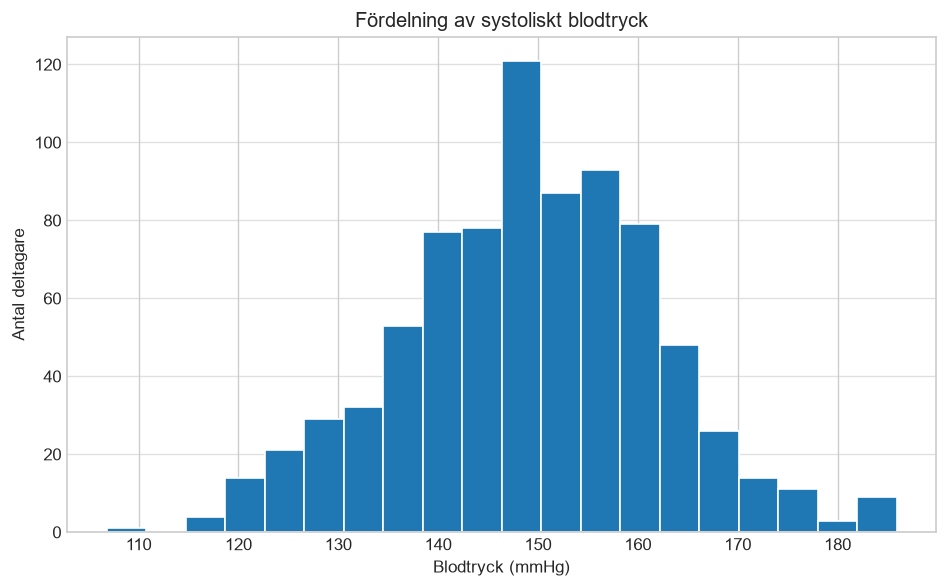

In [8]:
# Histogram för blodtryck
fig, ax = plt.subplots()
visualizer.hist(ax,"systolic_bp",
    "Fördelning av systoliskt blodtryck",
    "Blodtryck (mmHg)",
    "Antal deltagare"
)
fig.tight_layout()
plt.show()

**Tolkning:** Fördelningen liknar en normalfördelning. Den är klockformad och relativt symmetrisk. Men med en marginellt längre svans åt vänster, vilket kan tyda på en mycket svag vänsterskevhet. De flesta av observationerna ligger runt 150 mmHg i blodtryck.

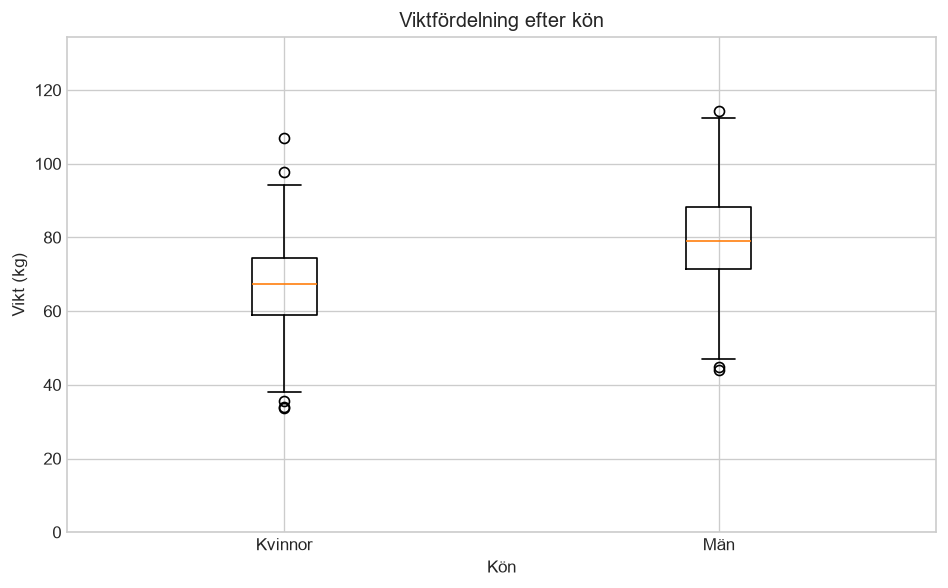

In [9]:
# Boxplot över vikt efter kön
visualizer.plot_weight_by_gender()

**Tolkning:** Viktfördelningen skiljer sig mellan män och kvinnor. Män har en högre medianvikt och större IQR, vilket betyder att vikten varierar mer bland män än bland kvinnor. Boxarna överlappar lite, men det finns ändå en tydlig skillnad mellan grupperna. Det finns ett extremvärde för högre vikt bland män och två bland kvinnor. För lägre vikter finns två extremvärden i båda grupperna. Medianen ligger längre ner i boxen för män och mer i mitten för kvinnor. Whiskers har ungefär samma längd ovanför som nedanför boxarna i båda grupperna. Det skulle kunna tyda på att viktfördelningen är ganska är symmetrisk.

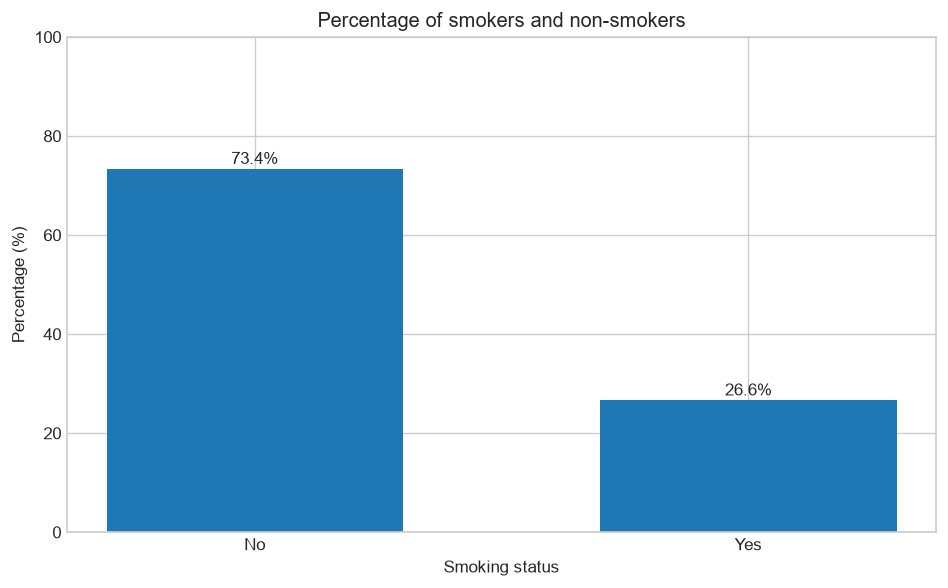

,antal,andel (%)
smoker,,
No,587,73.375
Yes,213,26.625


In [10]:
# Smoker summary
smoker_summary = analyzer.get_summary_smoker()
# Stapeldiagram över andelen rökare
# visualizer.plot_smoker(smoker_summary)
fig, ax = plt.subplots()
visualizer.barplot(
    ax,
    smoker_summary["andel (%)"].index,
    smoker_summary["andel (%)"].values,
    "Percentage of smokers and non-smokers",
    "Smoking status",
    "Percentage (%)",
    ylim=(0, 100),
    labels=True
)
fig.tight_layout()
plt.show()
display(smoker_summary)

**Tolkning:** Stapeldiagrammet visar fördelningen mellan rökare och icke-rökare i studien. 73,4% röker och 26,6% röker inte av de 800 som undersökts. Grupperna rökare och icke-rökare har alltså olika storlek.

## Simulering

Simuleringen undersöker hur mycket andelen personer med en sjukdom kan variera vid ett slumpmässigt urval av 1 000 personer. Binomialfördelningen används eftersom utfallet är binärt: en person är antingen sjuk eller inte (1 eller 0). Genom att sätta ett slumpmässigt seed blir simuleringen repeterbar och kan återskapas.

In [11]:
show_results("Simulering av sjukandel", analyzer.simulate_disease_proportion())

---------------------------------------------
           Simulering av sjukandel           
---------------------------------------------
Verklig andel       : 0.059
Simulerad andel     : 0.056
Verklig andel (%)   : 5.9
Simulerad andel (%) : 5.6
---------------------------------------------


**Tolkning:** Den verkliga sjukandelen är 5,9% och simulerad 5,6%. Dvs om vi har 1000 personer så är 59 av dem sjuka jämfört med 56 personer i simuleringen. Den simulerade sjukandelen ligger alltså nära den verkliga andelen i studien. Det observerade resultatet varierar mellan olika urval på grund av slumpmässig variation. Resultaten kan skilja sig åt även om sannolikheten för sjukdom är samma för varje person. Ju fler som ingår desto mindre slumpvariation och desto stabilare uppskattning. 

Begränsningar
- Simuleringen antar att varje person har samma sannolikhet att ha sjukdomen och att observationerna är oberoende av varandra. Det är en förenkling eftersom sjukdom i verkligheten kan påverkas av andra saker, såsom ålder, kön och livsstil.
- Simulering bygger på det befintliga datasetets sjukandel. Om det dataset inte är representativt för populationen så kan simuleringen bli missvisande.

## Konfidensintervall för blodtryckets medelvärde

#### Ett 95% konfidensintervall för medelvärdet med normalapproximation
Normalapproximationen är en enkel och relativt snabb metod som bygger på centrala gränsvärdessatsen (Practical Statistics for Data Scientists, 2020). Den innebär att en normalfördelning kan användas som approximation när stickprovet är tillräckligt stort och observationerna är tillräckligt oberoende. I studien ingår 800 personer. Därför fungerar metoden bra här. Den gör det möjligt att beräkna ett konfidensintervall för populationens medelvärde från stickprovets medelvärde och standardavvikelse. Konfidensintervallet beräknas med ett kritiskt z-värde på 1,96, vilket motsvarar en konfidensnivå på 95%.

In [12]:
ci_normal_results = analyzer.calc_ci_normal("systolic_bp")

show_results("95% KI (normal)", ci_normal_results)

---------------------------------------------
               95% KI (normal)               
---------------------------------------------
n                    : 800
sd                   : 12.793
Medelvärde           : 149.179
Standardfel          : 0.452
Nedre konfidensgräns : 148.292
Övre konfidensgräns  : 150.065
---------------------------------------------


**Tolkning:** Medelvärdet är 149,18 mmHg och det 95-procentiga konfidensintervallet ligger mellan 148,29 och 150,07 mmHg. Det innebär att det uppskattade genomsnittliga systoliska blodtrycket i populationen ligger inom intervallet med en konfidensnivå på 95 %. Eftersom det är ganska smalt så tyder det på att uppskattningen är relativt säker.

Begränsningar
- Normalapproximationen bygger på att stickprovet är tillräckligt stort och att observationerna är tillräckligt oberoende. 

- Metoden kan fungera sämre vid små stickprov eller om vi har många extrema värden. 
Om saknade värden har tagits bort, så kan det också påverka om bortfallet inte är slumpmässigt. Eftersom vi har ett stickprov på 800 personer så är normalapproximationen ganska robust. Men det kan hända att studiens 800 observationer inte är representativa för hela populationen.

- Populationens standardavvikelse är inte tillgänglig och får skattas från stickprovet. Det ger en viss osäkerhet i resultatet.

#### Ett 95% konfidensintervall för medelvärdet med bootstrap

Bootstrap väljs för att jämföra konfidensintervallen och få en bättre bild av osäkerheten. Metoden används för att skatta osäkerheten utan att behöva anta att datan är normalfördelad. Den innebär att ett antal nya stickprov skapas genom att slumpmässigt dra observationer från originaldatasetet med återläggning. För varje nytt stickprov beräknas ett medelvärde. Genom att upprepa processen 10 000 gånger kan man undersöka hur mycket medelvärdet varierar och på så sätt uppskatta osäkerheten.

In [13]:
ci_boot_results = analyzer.calc_ci_bootstrap(column="systolic_bp", n_boot = 10_000)

show_results("95% KI (bootstrap)", ci_boot_results)

---------------------------------------------
              95% KI (bootstrap)             
---------------------------------------------
Medelvärde           : 149.179
Nedre konfidensgräns : 148.307
Övre konfidensgräns  : 150.074
---------------------------------------------


**Tolkning:** Det beräknade 95-procentiga konfidensintervallet ligger mellan 148,31 och 150,07 mmHg. Det visar inom vilket intervall det sanna genomsnittliga blodtrycket i populationen förväntas ligga. Eftersom intervallet är ganska smalt tyder det på att uppskattningen är relativt säker. 

Begränsningar

- Bootstrap bygger på att urvalet är representativt. Om urvalet är för litet eller inte speglar populationen blir också konfidensintervallet missvisande.
- Bootstrapmetoden visar hur mycket medelvärdet kan variera beroende på vilka värden som finns med i stickprovet. Metoden kan alltså uppskatta slumpmässig osäkerhet, men kan inte korrigera exempelvis urvalsfel eller fel i datainsamlingen.

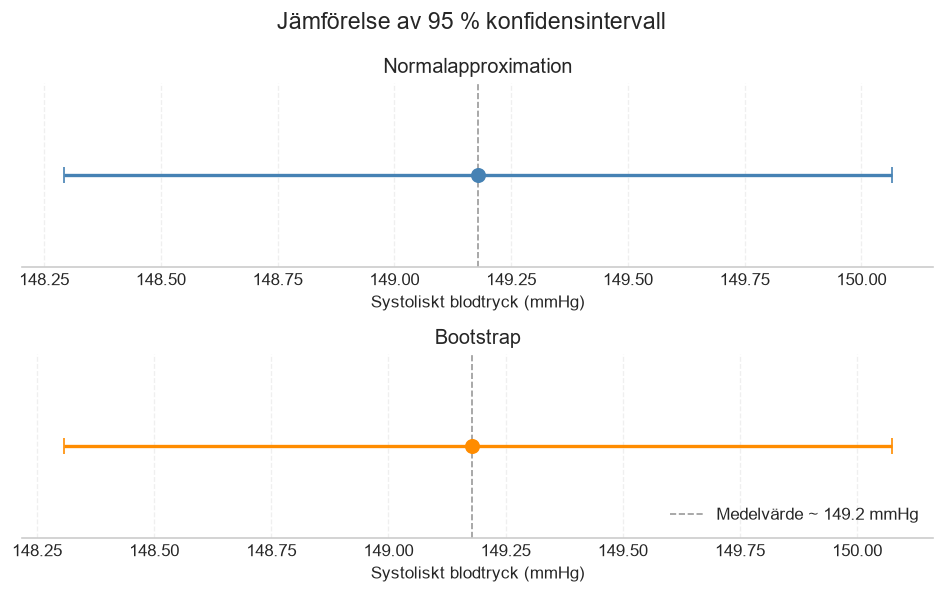

In [14]:

n, std_bp, mean_bp, standard_error, lower_normal, upper_normal = ci_normal_results.values()
_, lower_boot, upper_boot = ci_boot_results.values()

fig, ax = plt.subplots(2, 1, sharex=False)

# Normalapproximation
visualizer.errorbarplot(
    ax[0], mean_bp, lower_normal, upper_normal,
    "Normalapproximation",
    "Systoliskt blodtryck (mmHg)",
    "steelblue"
)

# Bootstrap
visualizer.errorbarplot(
    ax[1], mean_bp, lower_boot, upper_boot,
    "Bootstrap",
    "Systoliskt blodtryck (mmHg)",
    "darkorange"
)

fig.suptitle("Jämförelse av 95 % konfidensintervall", fontsize=14)

# Tar bort onödiga ramar
for a in ax:
    a.spines["top"].set_visible(False)
    a.spines["right"].set_visible(False)
    a.spines["left"].set_visible(False)

ax[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

In [21]:
show_results(
    "Systoliskt blodtryck",
    {
        "Antal observationer (n)": n,
        "Medelvärde (mmHg)": mean_bp,
        "Standardavvikelse (SD)": std_bp,
        "Standardfel (SE)": standard_error,

        "95% konfidensintervall": None,
        "Normalapproximation, nedre gräns": lower_normal,
        "Normalapproximation, övre gräns": upper_normal,
        "Bootstrap, nedre gräns": lower_boot,
        "Bootstrap, övre gräns": upper_boot
    }
)

---------------------------------------------
             Systoliskt blodtryck            
---------------------------------------------
Antal observationer (n)          : 800
Medelvärde (mmHg)                : 149.179
Standardavvikelse (SD)           : 12.793
Standardfel (SE)                 : 0.452

95% konfidensintervall
---------------------------------------------
Normalapproximation, nedre gräns : 148.292
Normalapproximation, övre gräns  : 150.065
Bootstrap, nedre gräns           : 148.307
Bootstrap, övre gräns            : 150.074
---------------------------------------------


**Jämförelse av de två 95-procentiga konfidensintervallen för systoliskt blodtryck**

- Normalapproximations-metoden använder medelvärdet och standardfelet för att uppskatta ett intervall där populationens sanna medelvärde förväntas ligga. Metoden bygger på att stickprovsmedelvärdet är ungefär normalfördelat, det är ofta rimligt vid tillräckligt stora stickprov.

- Bootstrap: Metoden skapar 10 000 nya stickprov genom slumpmässig dragning med återläggning från originaldatan. Medelvärdet beräknas för varje stickprov och de 2,5 och 97,5 percentilerna används som konfidensintervallets gränser.

- De två intervallens nedre och övre gränser är väldigt lika och tyder det på att metoderna ger ungefär samma uppskattning av osäkerheten. Intervallet är ganska smalt och det kan tyda på att skattningen är nära populationens medelvärde. Eftersom bägge ger ett liknande resultat så kan det bero på att datasetet är tillräckligt stort och observationerna är oberoende. Om resultatet hade varit olika hade det kunnat bero på fördelningen eller stickprovets egenskaper.

## Hypotesprövning ”Rökare har högre medel-blodtryck än icke-rökare”
Welch's t-test (ensidigt) har valts eftersom testet jämför medelvärdet mellan två oberoende grupper och fungerar också när grupperna har olika variation och antal. Det kräver inte lika varians. Welch's t-test förutsätter att observationerna är oberoende och att blodtrycket är någorlunda normalfördelat inom grupperna och att urvalen är tillräckligt stora för att testet ska vara robust. Här jämförs 213 rökare med 587 icke-rökare. Det är ensidigt eftersom vi vill undersöka om rökare har ett **högre** genomsnittligt blodtryck än icke-rökare. Signifikansnivån sätts till 5% (α = 0,05).

Testet utgår från hypoteserna:
- Nollhypotes (H₀): Rökare har inte ett högre medel-blodtryck än icke-rökare.
- Alternativhypotes (H₁): Rökare har ett högre medel-blodtryck än icke-rökare.
    - H₀: μR ≤ μIR
    - H₁: μR > μIR 


In [16]:
# Welchs t-test

smoker_data= analyzer.get_smoker_data()
(smokers, non_smokers, n_smokers, n_non_smokers, _, _,
 mean_smokers, mean_non_smokers, diff) = smoker_data

# Ensidigt t-test och variansen antas inte behöva vara lika
t_stat, p_value = stats.ttest_ind(
    smokers,
    non_smokers,
    equal_var=False,
    alternative="greater"
)

show_results(
    "Welch's t-test",
    {
        "Antal rökare": n_smokers,
        "Antal icke-rökare": n_non_smokers,
        "Medelvärde rökare": mean_smokers,
        "Medelvärde icke-rökare": mean_non_smokers,
        "Skillnad i medelvärde": diff,
        "t-statistika": t_stat,
        "p-värde": p_value
    }
)

if p_value < 0.05:
    print("Resultat: Vi förkastar nollhypotesen.")
    print("Det finns statistiskt stöd för att rökare har högre systoliskt blodtryck än icke-rökare")
else:
    print("Resultat: Vi kan inte förkasta nollhypotesen.")
    print("Det finns inte tillräckligt statistiskt stöd för att rökare har högre systoliskt blodtryck än icke-rökare")

---------------------------------------------
                Welch's t-test               
---------------------------------------------
Antal rökare           : 213
Antal icke-rökare      : 587
Medelvärde rökare      : 149.525
Medelvärde icke-rökare : 149.053
Skillnad i medelvärde  : 0.472
t-statistika           : 0.450
p-värde                : 0.326
---------------------------------------------
Resultat: Vi kan inte förkasta nollhypotesen.
Det finns inte tillräckligt statistiskt stöd för att rökare har högre systoliskt blodtryck än icke-rökare


**Tolkning:** 
Welch's t-test (ensidigt) ger en t-statistik på 0,450 och ett p-värde på 0,326. Eftersom p-värdet är större än signifikansnivån 0,05 kan vi inte förkasta nollhypotesen. Resultatet ger alltså inte statistiskt signifikant stöd för att rökare har ett högre genomsnittligt systoliskt blodtryck än icke-rökare. Det genomsnittliga systoliska blodtrycket var 149,53 mmHg hos rökare och 149,05 mmHg hos icke-rökare. Skillnaden mellan gruppernas medelvärden är cirka 0,47 mmHg. Även om rökarnas medelvärde är något högre är skillnaden liten och kan bero på slumpmässig variation. Det innebär inte att skillnaden saknas, utan att det inte finns tillräckligt statistiskt stöd för att dra slutsatsen att rökare har ett högre genomsnittligt systoliskt blodtryck än icke-rökare.

Begränsningar
- Welch t-test bygger på att grupperna ska vara oberoende av varandra och observationerna inom varje grupp ska vara oberoende. 
Blodtrycket antas vara ungefärligt normalfördelat inom grupperna, särskilt vid mindre urval.
- Testet undersöker skillnaden i medelvärden och tar inte hänsyn till andra faktorer som kan påverka blodtrycket, exempelvis ålder och livsstil.

## Gör en simulering för att undersöka hur säkert ditt hypotes­test är

Welchs t-test används för att jämföra rökare och icke-rökare och undersöka hur stora skillnader som krävs för att kunna upptäckas. Eftersom det är två oberoende grupper som jämförs så används ett ensidigt Welchs t-test även i simuleringarna. Simuleringarna används för att undersöka hur möjligheten att upptäcka en skillnad förändras beroende på hur skillnadens storlek mellan grupperna. För att undersöka testets styrka (power) görs 2 000 simuleringar för varje effektstorlek. Den första skillnaden är 0,47 mmHg motsvarar den ungefärliga skillnaden mellan grupperna i orginaldatat. Sedan ökas skillnaden mellan rökare och icke-rökare på för att undersöka hur det påverkar testets förmåga att upptäcka dem. De skillnader som testas är 0,47, 1, 2, 3 och 5 mmHg. En vanlig riktlinje är att testets power bör vara minst 80 %.

I varje simulering skapas två grupper med lika många personer och ungefär samma spridning i blodtrycket som i originaldatat. Därefter testas om rökarnas blodtryck är högre än icke-rökarnas, med en signifikansnivå på 0,05. 

**Power** beräknas genom att undersöka hur stor andel av simuleringarna som ger ett statistiskt signifikant resultat (p < 0,05). Power ger sannolikheten att testet upptäcker en skillnad i blodtryck mellan rökare och icke-rökare när en sådan finns. 

In [17]:
# Vad händer med power när skillnaden mellan grupperna ökar?
# Hur svårt är det att upptäcka skillnaderna mellan rökare och icke-rökare
n_sim = 2000
alpha = 0.05
effect_sizes = [0.47, 1, 2, 3, 5]

simulated_power = analyzer.run_power_analysis(
    effect_sizes, n_sim, alpha)

show_results("Effektmått och spridningsmått",
             {
                 "Standardavvikelse rökare": smokers.std(ddof=1),
                 "Standardavvikelse icke-rökare": non_smokers.std(ddof=1),
                 "Cohens d": analyzer.calculate_cohens_d()
             }
             )

display_summary = simulated_power.copy()
display_summary["power"] = (display_summary["power"] * 100).round(2)
display_summary = display_summary.rename(columns={"power": "power (%)"})

display(display_summary)

---------------------------------------------
        Effektmått och spridningsmått        
---------------------------------------------
Standardavvikelse rökare      : 13.268
Standardavvikelse icke-rökare : 12.626
Cohens d                      : 0.037
---------------------------------------------


,effekt,antal_signifikanta,power (%)
0,0.47,239,11.95
1,1.00,469,23.45
2,2.00,1149,57.45
3,3.00,1781,89.05
4,5.00,1997,99.85


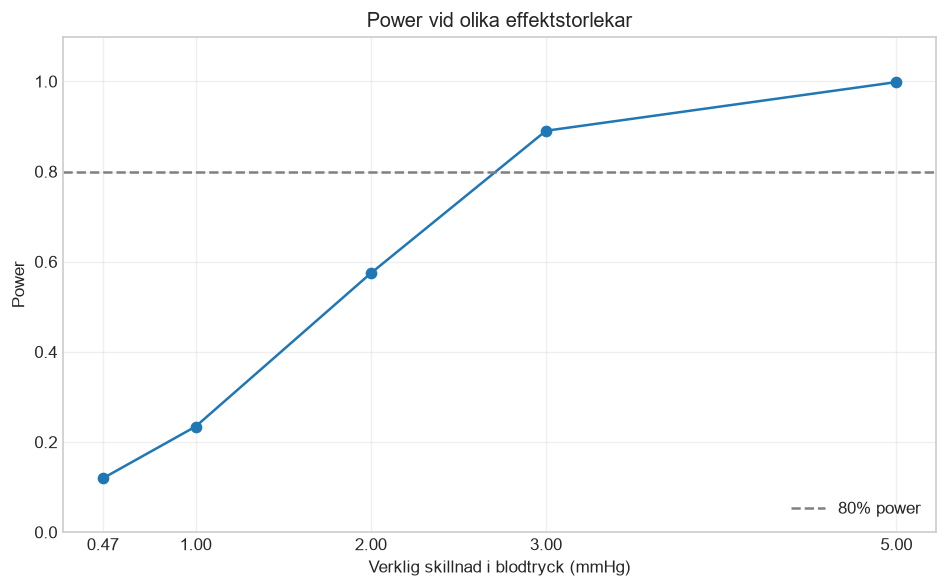

In [18]:
visualizer.plot_power(simulated_power)

**Tolkning:** Diagrammet visar att power ökar med effektstorlek. Vid små skillnader på 0,47 och 1 mmHg är sannolikheten att upptäcka en signifikant skillnad låg. Vid 2 mmHg ökar power till 57%, vid 3 mmHg är den 89%, medan en stor skillnad på 5 mmHg nästan alltid hittas. Det kan betyda att testet lättare upptäckar stora skillnader, men är sämre på att hitta små skillnader i blodtryck. Vid den minsta simulerade effektstorleken 0,47 mmHg är power 12,1%. Det kan vara en förklaring till att den ursprungliga hypotesprövningen inte blev statistiskt signifikant (p=0,326). 

Skillnaden mellan grupperna är 0,47 mmHg. Det kan innebära att skillnaden är svår att upptäcka om variansen är relativt hög. Standardavvikelsen är 13,27 för rökare och 12,63 för icke-rökare. Värdena varierar alltså ungefär lika mycket i båda grupperna. Enligt Cohens d motsvarar skillnaden mellan rökare och icke-rökare bara 0,04 standardavvikelser.

Begränsningar
- Power påverkas bland annat av effektstorlek, stickprovsstorlek, variation i data och signifikansnivå. 
- Små skillnader kräver ofta fler deltagare för att få tillräckligt hög power
- En hög power innebär mindre risk för typ II-fel, det vill säga att missa en verklig skillnad. 
- Effekstorlekarna som valts kanske inte motsvarar de skillnader som finns i populationen.